# Trabalho Final: Prevendo a Adesão a Depósitos a Prazo em Campanhas de Telemarketing Bancário

**Pós-graduação em IA Generativa e Aplicações com LLMs | PUC Minas | Machine Learning**
**Professor:** Maurício Rodrigues da Silva
**Aluno:** Rafael Brasil (trabalho individual)
**Data:** novembro de 2026

| Item | Descrição |
|---|---|
| **Dataset** | *Bank Marketing* (Moro, Cortez & Rita, 2014), UCI Machine Learning Repository, arquivo `bank-full.csv` (45.211 contatos, 17 colunas). Fonte: <https://archive.ics.uci.edu/dataset/222/bank+marketing> (DOI 10.24432/C5K306) |
| **Tipo de problema** | Classificação binária supervisionada |
| **Alvo** | `y`: o cliente contratou o depósito a prazo? (`yes` = 1, `no` = 0) |
| **Técnicas** | Regressão Logística, Random Forest e XGBoost (com *baseline* `DummyClassifier`), Grid Search CV, calibração das probabilidades (Platt) e ajuste de limiar |
| **Entrega** | Modelo exportado com `joblib` e consumido por uma API FastAPI + página web (`app/`) |
| **Repositório** | <https://github.com/rafaelmayerbrasil/trabalho-final-ml-bank-marketing> |

### O problema de negócio

Um banco português fez campanhas de telemarketing entre 2008 e 2010 para vender **depósitos a prazo**. Cada ligação custa tempo de atendente, e a maioria dos clientes recusa: só cerca de **12%** aceitaram. A pergunta do banco é:

> **Antes de ligar**, com os dados cadastrais e o histórico de contatos, dá para estimar a chance de o cliente aceitar e **priorizar** a fila de ligações?

O modelo **apoia** a decisão da equipe comercial (quem ligar primeiro); não substitui o atendente. Os dois tipos de erro têm custos diferentes:

- **Falso Negativo (FN):** o modelo diz "não vai aceitar" para quem aceitaria. O cliente sai da fila e o banco **perde uma venda**. É o erro mais caro.
- **Falso Positivo (FP):** o modelo diz "vai aceitar" para quem recusa. O banco gasta **uma ligação** à toa. Custa pouco.

Por isso o **Recall** da classe positiva merece atenção, sem abandonar a **Precisão** (ligar para todo mundo tem Recall 100% e não ajuda em nada). Usaremos o **ROC-AUC** para comparar modelos (independe do limiar) e o **F2** para escolher o limiar de decisão: é uma média entre Precisão e Recall que dá **peso dobrado ao Recall**, coerente com o FN ser o erro mais caro.

### Roteiro

| Etapa | Conteúdo |
|---|---|
| 1 | Importação de bibliotecas |
| 2 | Carregamento e inspeção |
| 3 | Análise exploratória (EDA) |
| 4 | Pré-processamento e split |
| 5 | Modelagem e comparação por validação cruzada |
| 6 | Otimização de hiperparâmetros e escolha do limiar |
| 7 | Avaliação final no conjunto de teste |
| 8 | Exportação do modelo |
| 9 | Conclusão |

---
## Etapa 1: Importação de Bibliotecas

Todas as bibliotecas ficam aqui, no início. A semente `np.random.seed(42)` e o `random_state=42` em todos os objetos aleatórios garantem que o notebook produza **os mesmos números** a cada execução.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import io
import json
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, brier_score_loss, log_loss)

np.random.seed(42)
SEED = 42

# Identidade visual dos gráficos (mesma paleta usada nas práticas da disciplina)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold'})
AZUL, TEAL, LARANJA, VERMELHO, CINZA = '#244357', '#23A8C3', '#F2A53D', '#C0504D', '#9AA5AE'

# Pastas do projeto
PASTA_DADOS = Path('dados');   PASTA_DADOS.mkdir(exist_ok=True)
PASTA_MODELO = Path('modelo'); PASTA_MODELO.mkdir(exist_ok=True)
PASTA_FIG = Path('figuras');   PASTA_FIG.mkdir(exist_ok=True)

def salvar(fig, nome):
    # Salva a figura em figuras/ para usar no relatório em PDF.
    fig.savefig(PASTA_FIG / f'{nome}.png', dpi=150, bbox_inches='tight')

print(f'numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | '
      f'xgboost {xgboost.__version__} | joblib {joblib.__version__}')

numpy 2.4.1 | pandas 2.3.3 | scikit-learn 1.9.1 | xgboost 3.4.1 | joblib 1.6.0


---
## Etapa 2: Carregamento e Inspeção dos Dados

O notebook procura o arquivo em `dados/bank-full.csv` (incluído na entrega) e, em seguida, em `../dataset/bank-full.csv` (pasta de datasets da disciplina). Só se nenhum dos dois existir (por exemplo, rodando no Google Colab) ele **baixa automaticamente** o pacote oficial da UCI e extrai o CSV. O separador do arquivo é `;`.

### Dicionário de dados

| Coluna | Tipo | Significado |
|---|---|---|
| `age` | numérica | idade do cliente (anos) |
| `job` | categórica | profissão (12 categorias, inclui `unknown`) |
| `marital` | categórica | estado civil (`married`, `single`, `divorced`) |
| `education` | categórica | escolaridade (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binária | tem crédito em atraso (inadimplente)? |
| `balance` | numérica | saldo médio anual em conta (euros) |
| `housing` | binária | tem financiamento imobiliário? |
| `loan` | binária | tem empréstimo pessoal? |
| `contact` | categórica | meio de contato (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | dia do mês do último contato |
| `month` | categórica | mês do último contato |
| `duration` | numérica | duração do último contato (segundos). **Só é conhecida depois da ligação** |
| `campaign` | numérica | nº de contatos nesta campanha (inclui o último) |
| `pdays` | numérica | dias desde o último contato da campanha anterior (`-1` = nunca contatado) |
| `previous` | numérica | nº de contatos antes desta campanha |
| `poutcome` | categórica | resultado da campanha anterior (`success`, `failure`, `other`, `unknown`) |
| `y` | **alvo** | contratou o depósito a prazo? (`yes`/`no`) |

In [2]:
CAMINHO_CSV = PASTA_DADOS / 'bank-full.csv'
URL_UCI = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'

if not CAMINHO_CSV.exists() and Path('../dataset/bank-full.csv').exists():
    CAMINHO_CSV = Path('../dataset/bank-full.csv')
if not CAMINHO_CSV.exists():
    print('Arquivo local não encontrado. Baixando da UCI...')
    with urllib.request.urlopen(URL_UCI) as resp:
        externo = zipfile.ZipFile(io.BytesIO(resp.read()))
    interno = zipfile.ZipFile(io.BytesIO(externo.read('bank.zip')))
    CAMINHO_CSV.write_bytes(interno.read('bank-full.csv'))

dados = pd.read_csv(CAMINHO_CSV, sep=';')
print(f'Formato: {dados.shape[0]:,} linhas x {dados.shape[1]} colunas'.replace(',', '.'))
dados.head()

Formato: 45.211 linhas x 17 colunas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
print('Valores nulos (NaN) por coluna:', int(dados.isna().sum().sum()))
print('Linhas duplicadas:', int(dados.duplicated().sum()))

# Nulos "escondidos": a base usa o texto 'unknown' no lugar de NaN
desconhecidos = (dados.select_dtypes('object') == 'unknown').sum()
desconhecidos = desconhecidos[desconhecidos > 0].sort_values(ascending=False)
pd.DataFrame({'qtd_unknown': desconhecidos,
              '% da base': (desconhecidos / len(dados) * 100).round(1)})

Valores nulos (NaN) por coluna: 0


Linhas duplicadas: 0


,qtd_unknown,% da base
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6


In [5]:
dados.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


In [6]:
dados.describe(include='object').T

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


**O que a inspeção mostra**

- **Sem `NaN` e sem duplicatas.** Mas a base tem **valores faltantes disfarçados** de `'unknown'`: 82% em `poutcome`, 29% em `contact`, 4% em `education` e menos de 1% em `job`. Em `poutcome`, `unknown` quase sempre significa "cliente nunca foi contatado antes" (é o caso de todos os `pdays = -1`), então **carrega informação** e não deve ser apagado nem imputado. A decisão é tratar `unknown` como **uma categoria própria**.
- **`pdays = -1`** é um código especial para "nunca contatado", não um número de dias. Mais de 75% dos clientes estão nessa situação.
- **Assimetrias fortes:** `balance` vai de −8.019 a 102.127 euros (mediana 448), `campaign` chega a 63 ligações e `previous` a 275. São valores raros mas plausíveis; o pré-processamento com `StandardScaler` (para modelos lineares) e modelos de árvore (insensíveis à escala) lida com isso sem precisar remover linhas.
- Há 9 colunas categóricas que precisarão de **encoding**.

---
## Etapa 3: Análise Exploratória (EDA)

Seis gráficos, cada um com uma pergunta e uma interpretação: **(1)** distribuição do alvo, **(2)** distribuições das variáveis numéricas, **(3)** correlação, **(4)** sazonalidade (domínio), **(5)** perfil do cliente e histórico (domínio) e **(6)** o caso da coluna `duration`.

Para facilitar as contas, criamos uma versão numérica do alvo (`alvo`: 1 = contratou).

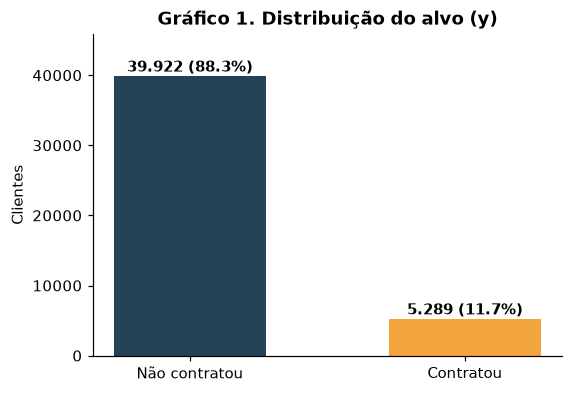

In [7]:
dados['alvo'] = (dados['y'] == 'yes').astype(int)
TAXA_GERAL = dados['alvo'].mean()

contagem = dados['y'].value_counts().reindex(['no', 'yes'])
pct = contagem / contagem.sum() * 100

fig, ax = plt.subplots(figsize=(5.5, 3.8))
barras = ax.bar(['Não contratou', 'Contratou'], contagem.values, color=[AZUL, LARANJA], width=0.55)
for b, q, p in zip(barras, contagem.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, q + 600, f'{q:,} ({p:.1f}%)'.replace(',', '.'),
            ha='center', fontweight='bold')
ax.set_ylabel('Clientes'); ax.set_ylim(0, contagem.max() * 1.15)
ax.set_title('Gráfico 1. Distribuição do alvo (y)')
salvar(fig, 'g1_alvo'); plt.show()

**Gráfico 1: interpretação.** Só **11,7%** dos clientes contrataram: a base é **fortemente desbalanceada** (cerca de 7,5 "não" para cada "sim"). Um modelo "preguiçoso" que sempre respondesse "não contrata" teria **88% de acurácia** sem encontrar nenhum cliente interessado. Consequências práticas para o projeto:

1. a **acurácia não serve** como métrica principal; olharemos Precisão, Recall, F1, ROC-AUC e PR-AUC;
2. o split treino/teste e a validação cruzada precisam ser **estratificados**, para manter os 11,7% em todas as partes;
3. os modelos usarão **pesos de classe** (`class_weight` / `scale_pos_weight`) para não ignorar a classe rara.

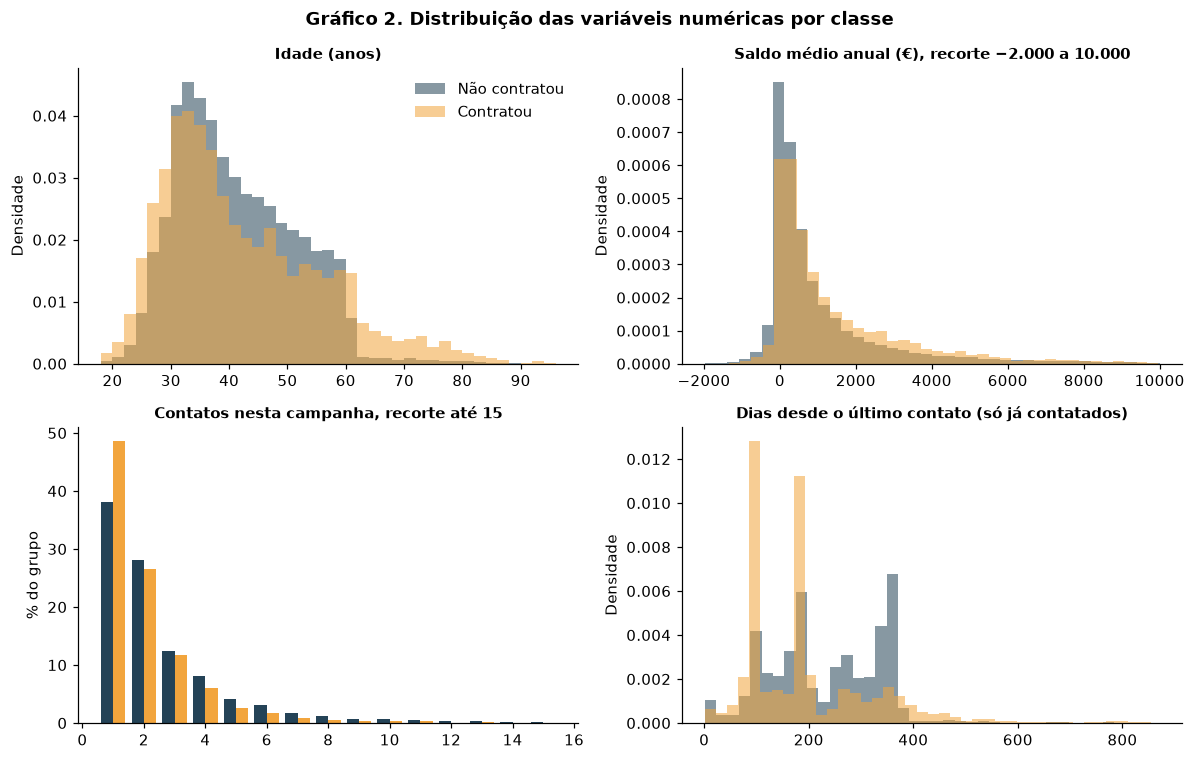

Mediana por classe:
      age  balance  campaign  previous
y                                     
no   39.0    417.0       2.0       0.0
yes  38.0    733.0       2.0       0.0


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
config = [('age', 'Idade (anos)', (18, 95)),
          ('balance', 'Saldo médio anual (€), recorte −2.000 a 10.000', (-2000, 10000)),
          ('campaign', 'Contatos nesta campanha, recorte até 15', (1, 15)),
          ('pdays', 'Dias desde o último contato (só já contatados)', (1, 871))]
for ax, (col, titulo, (lo, hi)) in zip(axes.ravel(), config):
    base = dados[(dados[col] >= lo) & (dados[col] <= hi)]
    if col == 'campaign':
        tab = base.groupby(['campaign', 'y']).size().unstack(fill_value=0)
        tab = tab.div(tab.sum(axis=0), axis=1) * 100
        largura = 0.4
        ax.bar(tab.index - largura / 2, tab['no'], largura, color=AZUL, label='Não contratou')
        ax.bar(tab.index + largura / 2, tab['yes'], largura, color=LARANJA, label='Contratou')
        ax.set_ylabel('% do grupo')
    else:
        for rotulo, cor, nome in [('no', AZUL, 'Não contratou'), ('yes', LARANJA, 'Contratou')]:
            bins = np.arange(18, 97, 2) if col == 'age' else 40   # idade: faixas de 2 anos (evita falhas de arredondamento)
            ax.hist(base.loc[base['y'] == rotulo, col], bins=bins, density=True, alpha=0.55,
                    color=cor, label=nome)
        ax.set_ylabel('Densidade')
    ax.set_title(titulo, fontsize=10)
axes[0, 0].legend(frameon=False)
fig.suptitle('Gráfico 2. Distribuição das variáveis numéricas por classe', fontweight='bold')
fig.tight_layout()
salvar(fig, 'g2_distribuicoes'); plt.show()

print('Mediana por classe:')
print(dados.groupby('y')[['age', 'balance', 'campaign', 'previous']].median())

**Gráfico 2: interpretação.** As distribuições normalizadas (densidade) permitem comparar as duas classes mesmo com tamanhos muito diferentes:

- **Idade:** quem contrata se concentra nos **extremos**, abaixo de 30 e acima de 60 anos (estudantes e aposentados). O miolo de 30 a 55 anos, maioria da base, contrata menos. A relação **não é linear**, o que favorece modelos de árvore.
- **Saldo:** muito assimétrico, com cauda longa à direita. Quem contrata tem saldo mediano quase **duas vezes maior** (733 € contra 417 €), mas as distribuições se sobrepõem bastante.
- **Contatos na campanha:** a proporção de quem contrata é maior quando houve **1 contato** e cai à medida que o número de ligações aumenta. Insistir demais com o mesmo cliente rende pouco.
- **`pdays`:** entre os já contatados, há picos perto de 90, 180 e 365 dias (ciclos de campanha). Quem contrata se concentra nos picos de **90 e 180 dias**; quem recusa, no de **≈ 1 ano**: um contato recente na campanha anterior favorece a adesão. Lembrando que 82% da base tem `pdays = -1` e ficou fora deste painel.

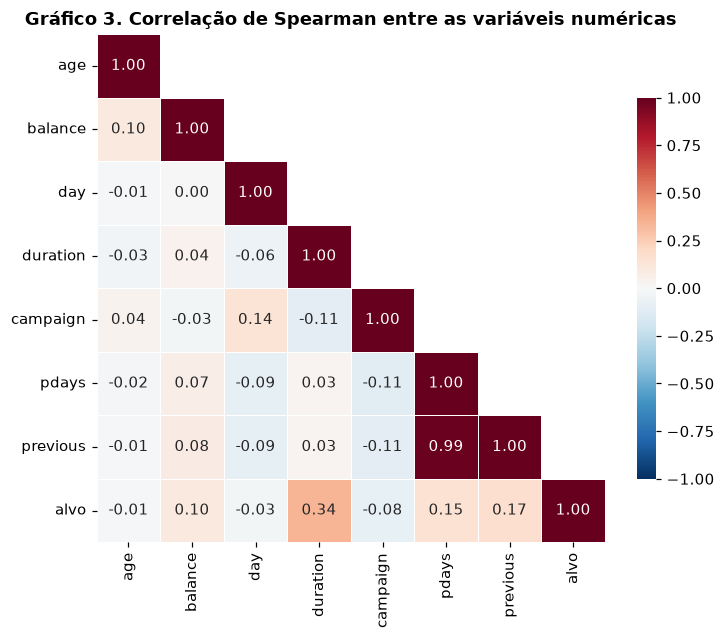

duration    0.342
previous    0.169
pdays       0.154
balance     0.100
campaign   -0.084
day        -0.030
age        -0.009
Name: alvo, dtype: float64

In [9]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'alvo']
corr = dados[num_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7.5, 6))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.75}, ax=ax)
ax.set_title('Gráfico 3. Correlação de Spearman entre as variáveis numéricas')
salvar(fig, 'g3_correlacao'); plt.show()

corr['alvo'].drop('alvo').sort_values(key=abs, ascending=False).round(3)

**Gráfico 3: interpretação.** Usamos a correlação de **Spearman** (baseada em postos) porque as variáveis são assimétricas e cheias de valores extremos; Pearson seria distorcido por eles.

- A variável mais associada ao alvo é **`duration` (0,34)**, de longe. Isso é um alerta, e não uma boa notícia: discutimos no Gráfico 6.
- Depois vêm **`previous` (0,17)** e **`pdays` (0,15)**: já ter sido contatado em campanha anterior está ligado a contratar. O saldo (`balance`, 0,10) vem em seguida.
- `campaign` tem correlação **negativa** (−0,08): mais ligações, menor chance, como vimos no Gráfico 2.
- `pdays` e `previous` são quase redundantes entre si (0,99), porque ambos codificam "já foi contatado?". Para os modelos de árvore isso não atrapalha; na Regressão Logística a regularização L2 reparte o peso entre as duas.
- Nenhuma correlação isolada com o alvo é forte: o poder preditivo vai vir da **combinação** de variáveis, inclusive as categóricas, que este gráfico não mostra.

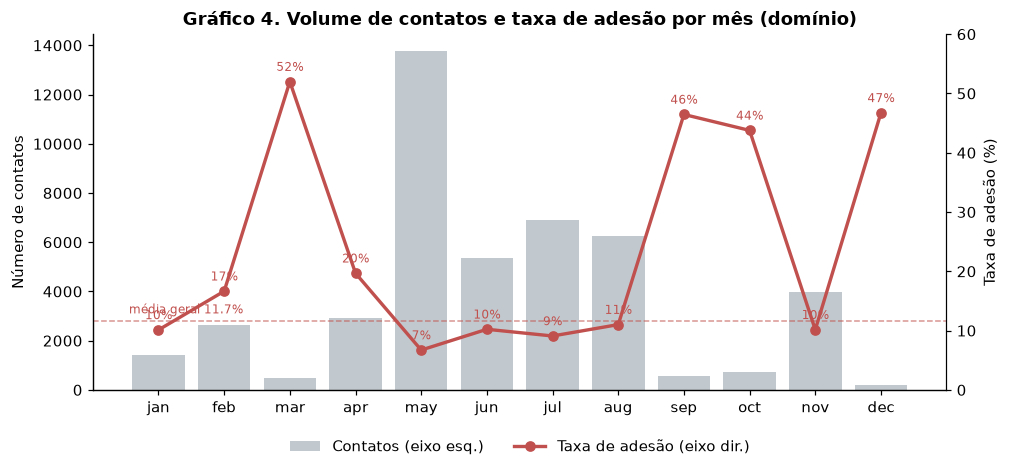

In [10]:
ordem_meses = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
por_mes = dados.groupby('month').agg(contatos=('alvo', 'size'), taxa=('alvo', 'mean')).reindex(ordem_meses)

fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(ordem_meses, por_mes['contatos'], color=CINZA, alpha=0.6, label='Contatos (eixo esq.)')
ax1.set_ylabel('Número de contatos')
ax2 = ax1.twinx()
ax2.plot(ordem_meses, por_mes['taxa'] * 100, color=VERMELHO, marker='o', lw=2.2, label='Taxa de adesão (eixo dir.)')
ax2.axhline(TAXA_GERAL * 100, color=VERMELHO, ls='--', lw=1, alpha=0.6)
ax2.text(-0.45, TAXA_GERAL * 100 + 1.2, f'média geral {TAXA_GERAL:.1%}', color=VERMELHO, ha='left', fontsize=8)
ax2.set_ylabel('Taxa de adesão (%)'); ax2.spines['right'].set_visible(True)
for x, t in zip(ordem_meses, por_mes['taxa']):
    ax2.annotate(f'{t:.0%}', (x, t * 100), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8, color=VERMELHO)
linhas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(linhas, [l.get_label() for l in linhas], frameon=False, loc='upper center',
           bbox_to_anchor=(0.5, -0.1), ncol=2)
ax2.set_ylim(0, 60)
ax1.set_title('Gráfico 4. Volume de contatos e taxa de adesão por mês (domínio)')
salvar(fig, 'g4_mes'); plt.show()

**Gráfico 4: interpretação.** Este é o gráfico de **domínio** mais revelador: volume e eficiência andam em **direções opostas**.

- **Maio** concentra 30% de todos os contatos e tem a **pior taxa de adesão (≈ 7%)**. Junho, julho e agosto também têm muito volume e taxa abaixo ou próxima da média.
- **Março, setembro, outubro e dezembro** têm pouquíssimos contatos e taxas de **44% a 52%**, quatro vezes a média.

Uma leitura de negócio: nos meses de campanha "em massa" o banco liga para todo mundo (inclusive clientes pouco propensos), enquanto nos meses de baixo volume as ligações parecem ser mais seletivas (por exemplo, clientes que já tinham aceitado antes). Ou seja, `month` captura em parte **a estratégia da campanha**, não só a sazonalidade. O modelo vai usar essa informação, mas ela é um ponto de atenção: se a estratégia mudar, a relação pode mudar também (discutido nas limitações).

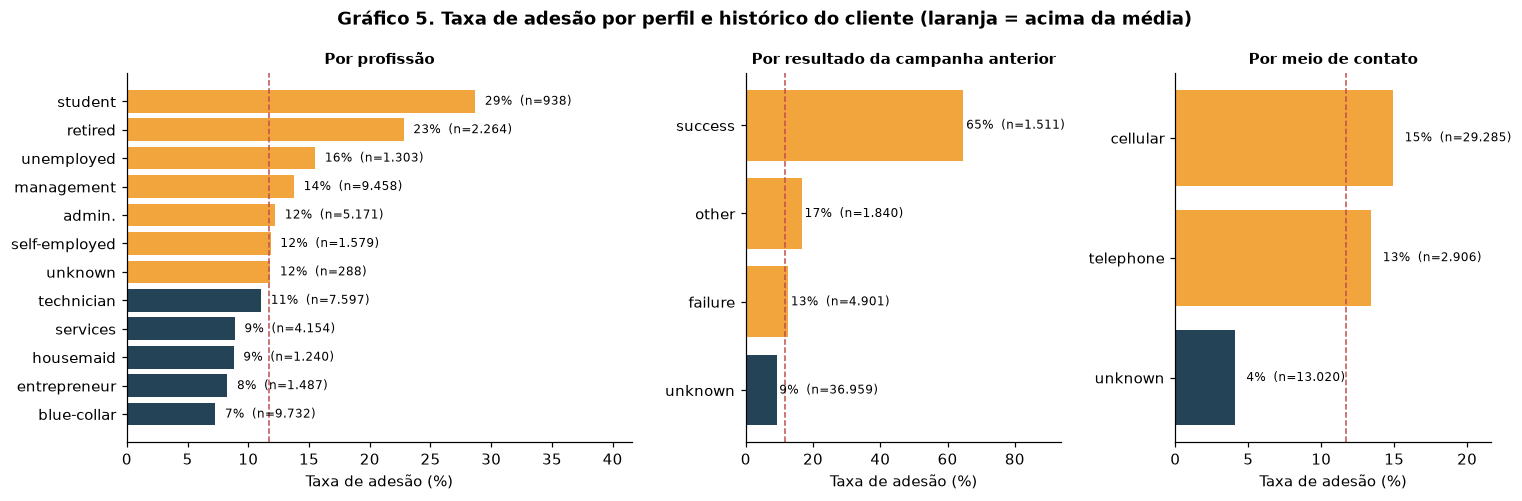

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})

def barras_taxa(ax, coluna, titulo, ordenar=True):
    tab = dados.groupby(coluna)['alvo'].agg(['mean', 'size'])
    if ordenar:
        tab = tab.sort_values('mean')
    cores = [LARANJA if t > TAXA_GERAL else AZUL for t in tab['mean']]
    ax.barh(tab.index, tab['mean'] * 100, color=cores)
    ax.axvline(TAXA_GERAL * 100, color=VERMELHO, ls='--', lw=1)
    for i, (t, n) in enumerate(zip(tab['mean'], tab['size'])):
        ax.text(t * 100 + 0.8, i, f'{t:.0%}  (n={n:,})'.replace(',', '.'), va='center', fontsize=8)
    ax.set_xlim(0, tab['mean'].max() * 100 * 1.45)
    ax.set_xlabel('Taxa de adesão (%)'); ax.set_title(titulo, fontsize=10)

barras_taxa(axes[0], 'job', 'Por profissão')
barras_taxa(axes[1], 'poutcome', 'Por resultado da campanha anterior')
barras_taxa(axes[2], 'contact', 'Por meio de contato')
fig.suptitle('Gráfico 5. Taxa de adesão por perfil e histórico do cliente (laranja = acima da média)',
             fontweight='bold')
fig.tight_layout()
salvar(fig, 'g5_perfil'); plt.show()

**Gráfico 5: interpretação.** A linha tracejada é a média geral (11,7%).

- **Profissão:** **estudantes (29%)** e **aposentados (23%)** contratam bem acima da média, coerente com o padrão de idade do Gráfico 2 (públicos com tempo e/ou dinheiro parado). Operários (`blue-collar`, 7%) e empreendedores ficam bem abaixo.
- **Campanha anterior:** é a variável categórica mais forte. Quem **aceitou na campanha passada (`success`) aceita de novo em 65%** dos casos, mais de cinco vezes a média. É o tipo de regra que a equipe comercial reconhece, e o modelo deve aprendê-la.
- **Meio de contato:** quando o meio é `unknown`, a taxa despenca para **4%**. Isso confirma a decisão da Etapa 2: `unknown` não é um "buraco" a ser preenchido com a moda, é um **sinal** (provavelmente um período ou uma forma de registro da campanha), e por isso fica como categoria própria.

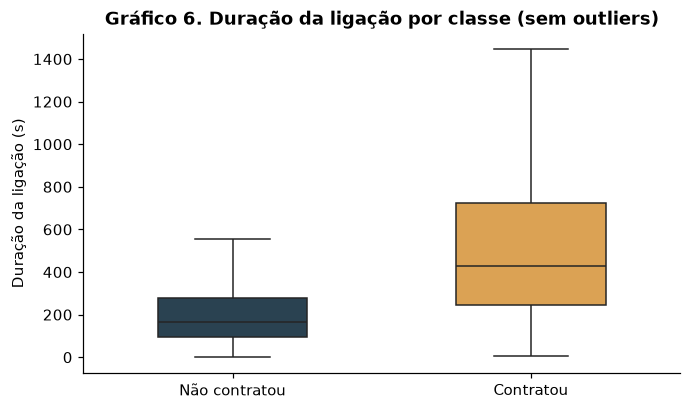

Duração mediana (s): {'no': 164.0, 'yes': 426.0}
Ligações com duration = 0 que resultaram em "yes": 0


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=dados, x='y', y='duration', order=['no', 'yes'], palette=[AZUL, LARANJA],
            showfliers=False, width=0.5, ax=ax)
ax.set_xticklabels(['Não contratou', 'Contratou']); ax.set_xlabel('')
ax.set_ylabel('Duração da ligação (s)')
ax.set_title('Gráfico 6. Duração da ligação por classe (sem outliers)')
salvar(fig, 'g6_duration'); plt.show()

print('Duração mediana (s):', dados.groupby('y')['duration'].median().to_dict())
print('Ligações com duration = 0 que resultaram em "yes":', int(((dados['duration'] == 0) & (dados['alvo'] == 1)).sum()))

**Gráfico 6: interpretação e decisão de projeto.** Quem contratou falou, em mediana, **426 s** ao telefone; quem recusou, **164 s**. A diferença é enorme, e é exatamente por isso que `duration` **precisa sair do modelo**:

- a duração **só é conhecida depois que a ligação termina**, e a ligação longa é em boa parte **consequência** da venda (explicar o produto, fechar o contrato), não causa;
- o objetivo do banco é decidir **para quem ligar antes de ligar**. Nesse momento a duração não existe;
- a descrição da variável na página do dataset na UCI recomenda descartá-la quando o objetivo é um modelo preditivo realista (o arquivo `bank-names.txt` não traz esse aviso; ele está no site e no `bank-additional-names.txt` da versão ampliada).

Manter `duration` daria uma AUC artificialmente alta (vazamento de informação do futuro, o *data leakage*) e um modelo inútil na prática. **Decisão: `duration` é removida** antes do split. As demais 15 variáveis são todas conhecidas antes do contato.

---
## Etapa 4: Pré-processamento e Split Treino/Teste

### Decisões

| Etapa | Decisão | Justificativa |
|---|---|---|
| Vazamento | remover `duration` | conhecida só após a ligação (Gráfico 6) |
| Nulos `NaN` | `SimpleImputer` (mediana / moda) dentro do Pipeline | a base não tem `NaN` hoje, mas o imputador protege a API contra campos ausentes no futuro |
| `'unknown'` | manter como categoria | carrega informação (Gráfico 5) |
| `pdays = -1` | manter o código | junto com `poutcome = unknown` e `previous = 0`, o modelo identifica "nunca contatado"; árvores tratam o código sem problema |
| Encoding | `OneHotEncoder(handle_unknown='ignore')` | variáveis nominais sem ordem; categorias novas na API não quebram a predição |
| Normalização | `StandardScaler` nas numéricas | necessária para a Regressão Logística; inofensiva para árvores |
| Split | 80% treino / 20% teste, **estratificado**, `random_state=42` | mantém os 11,7% de positivos nas duas partes |

Tudo fica dentro de um **`Pipeline` + `ColumnTransformer`**: o imputador e o scaler aprendem médias e desvios **só com os dados de treino** de cada dobra da validação cruzada. Isso evita vazamento entre treino e validação.

In [13]:
ALVO = 'alvo'
COLUNAS_REMOVIDAS = ['duration', 'y']        # duration = vazamento; y = alvo em texto
NUMERICAS = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
CATEGORICAS = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
FEATURES = NUMERICAS + CATEGORICAS

X = dados[FEATURES].copy()
y = dados[ALVO].copy()

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f'Features usadas: {len(FEATURES)} ({len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas)')
print(f'Treino: {X_treino.shape[0]:,} linhas | % positivos = {y_treino.mean():.2%}'.replace(',', '.'))
print(f'Teste : {X_teste.shape[0]:,} linhas | % positivos = {y_teste.mean():.2%}'.replace(',', '.'))

Features usadas: 15 (6 numéricas + 9 categóricas)
Treino: 36.168 linhas | % positivos = 11.70%
Teste : 9.043 linhas | % positivos = 11.70%


In [14]:
def criar_preprocessador():
    numerico = Pipeline([('imputador', SimpleImputer(strategy='median')),
                         ('scaler', StandardScaler())])
    categorico = Pipeline([('imputador', SimpleImputer(strategy='most_frequent')),
                           ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', numerico, NUMERICAS),
                              ('cat', categorico, CATEGORICAS)])

# Só para inspecionar o resultado: o preprocessador ajustado no treino gera a matriz de entrada
pre_demo = criar_preprocessador().fit(X_treino)
nomes_saida = pre_demo.get_feature_names_out()
print(f'Depois do encoding: {len(nomes_saida)} colunas de entrada para o modelo')
print('Exemplos:', list(nomes_saida[:8]), '...')
pd.DataFrame(pre_demo.transform(X_treino.head(3)), columns=nomes_saida).iloc[:, :10].round(2)

Depois do encoding: 50 colunas de entrada para o modelo
Exemplos: ['num__age', 'num__balance', 'num__day', 'num__campaign', 'num__pdays', 'num__previous', 'cat__job_admin.', 'cat__job_blue-collar'] ...


,num__age,num__balance,num__day,num__campaign,num__pdays,num__previous,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid
0,-0.46,-0.16,1.58,-0.25,-0.41,-0.24,0.0,0.0,0.0,0.0
1,-1.59,0.90,-1.30,0.40,1.45,2.66,0.0,0.0,0.0,0.0
2,0.29,-0.37,-0.46,0.40,-0.41,-0.24,0.0,0.0,0.0,0.0


---
## Etapa 5: Modelagem e Comparação por Validação Cruzada

Comparamos quatro abordagens, todas dentro do mesmo Pipeline:

| Modelo | Por que testar |
|---|---|
| `DummyClassifier` (estratificado) | *baseline*: o que se obtém "chutando" na proporção das classes. Qualquer modelo útil precisa superá-lo |
| Regressão Logística | modelo linear, interpretável, rápido; referência clássica |
| Random Forest | conjunto de árvores (*bagging*); capta não linearidades (idade) e interações |
| XGBoost | *gradient boosting*; costuma ser o estado da arte em dados tabulares |

Os três modelos reais recebem **peso maior para a classe positiva** (`class_weight='balanced'` ou `scale_pos_weight` ≈ 7,5), para compensar o desbalanceamento.

A comparação usa **validação cruzada estratificada com 5 dobras** apenas no **treino**: o conjunto de teste fica guardado e só será usado **uma vez**, na Etapa 7. Nesta etapa as métricas dependentes de limiar (Precisão, Recall, F1) usam o limiar padrão de 0,5.

In [15]:
peso_positivo = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f'scale_pos_weight (negativos/positivos no treino) = {peso_positivo:.2f}')

modelos = {
    'Dummy (baseline)': DummyClassifier(strategy='stratified', random_state=SEED),
    'Regressão Logística': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=peso_positivo,
                             eval_metric='logloss', n_jobs=-1, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision', 'F1': 'f1',
               'Recall': 'recall', 'Precisão': 'precision', 'Acurácia': 'accuracy'}

resultados_cv, auc_por_dobra = {}, {}
for nome, estimador in modelos.items():
    pipe = Pipeline([('preprocessador', criar_preprocessador()), ('modelo', estimador)])
    r = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=metricas_cv)
    resultados_cv[nome] = {m: r[f'test_{m}'].mean() for m in metricas_cv}
    resultados_cv[nome]['Desvio ROC-AUC'] = r['test_ROC-AUC'].std()
    auc_por_dobra[nome] = r['test_ROC-AUC']
    print(f'{nome:<22} ROC-AUC = {r["test_ROC-AUC"].mean():.3f} ± {r["test_ROC-AUC"].std():.3f}')

tabela_cv = pd.DataFrame(resultados_cv).T.sort_values('ROC-AUC', ascending=False)
tabela_cv.round(3)

scale_pos_weight (negativos/positivos no treino) = 7.55


Dummy (baseline)       ROC-AUC = 0.499 ± 0.003


Regressão Logística    ROC-AUC = 0.764 ± 0.003


Random Forest          ROC-AUC = 0.793 ± 0.004


XGBoost                ROC-AUC = 0.796 ± 0.002


,ROC-AUC,PR-AUC,F1,Recall,Precisão,Acurácia,Desvio ROC-AUC
XGBoost,0.796,0.448,0.450,0.611,0.356,0.825,0.002
Random Forest,0.793,0.441,0.472,0.515,0.436,0.865,0.004
Regressão Logística,0.764,0.398,0.373,0.622,0.266,0.755,0.003
Dummy (baseline),0.499,0.117,0.115,0.114,0.115,0.794,0.003


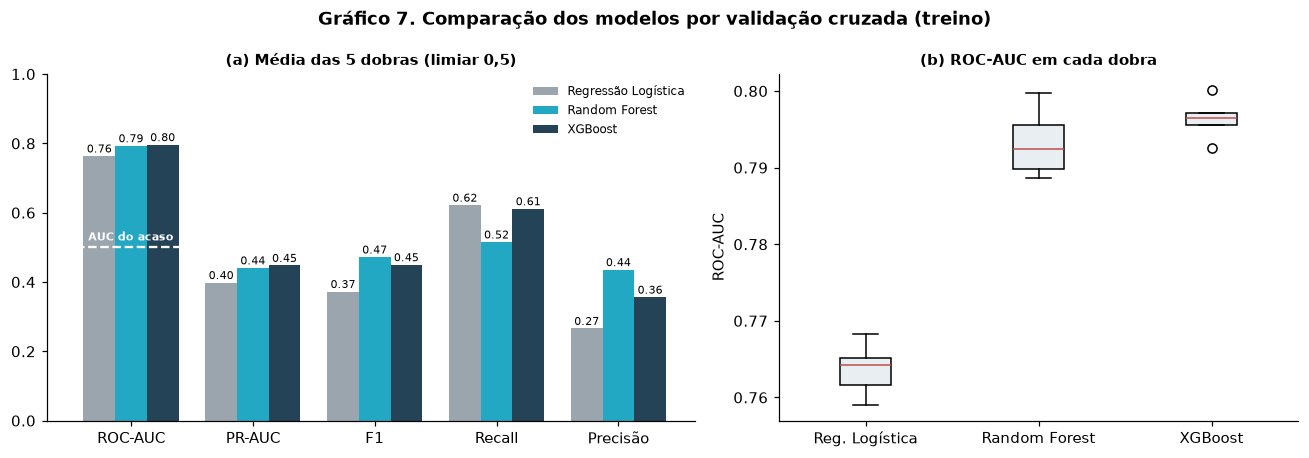

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.25, 1]})

# (a) métricas médias por modelo
ordem = ['Regressão Logística', 'Random Forest', 'XGBoost']
metr = ['ROC-AUC', 'PR-AUC', 'F1', 'Recall', 'Precisão']
cores = {'Regressão Logística': CINZA, 'Random Forest': TEAL, 'XGBoost': AZUL}
largura = 0.26
for i, nome in enumerate(ordem):
    vals = [tabela_cv.loc[nome, m] for m in metr]
    pos = np.arange(len(metr)) + (i - 1) * largura
    axes[0].bar(pos, vals, largura, color=cores[nome], label=nome)
    for p, v in zip(pos, vals):
        axes[0].text(p, v + 0.01, f'{v:.2f}', ha='center', fontsize=7)
axes[0].plot([-0.45, 0.45], [0.5, 0.5], color='white', ls='--', lw=1.5)
axes[0].text(0, 0.52, 'AUC do acaso', color='white', fontsize=7.5, ha='center', fontweight='bold')
axes[0].set_xticks(range(len(metr))); axes[0].set_xticklabels(metr)
axes[0].set_ylim(0, 1); axes[0].legend(frameon=False, fontsize=8, loc='upper right')
axes[0].set_title('(a) Média das 5 dobras (limiar 0,5)', fontsize=10)

# (b) estabilidade do ROC-AUC entre as dobras
axes[1].boxplot([auc_por_dobra[n] for n in ordem], tick_labels=['Reg. Logística', 'Random Forest', 'XGBoost'],
                patch_artist=True, boxprops=dict(facecolor='#E8EEF2'), medianprops=dict(color=VERMELHO))
axes[1].set_ylabel('ROC-AUC'); axes[1].set_title('(b) ROC-AUC em cada dobra', fontsize=10)

fig.suptitle('Gráfico 7. Comparação dos modelos por validação cruzada (treino)', fontweight='bold')
fig.tight_layout()
salvar(fig, 'g7_comparacao_cv'); plt.show()

**Leitura da comparação.**

- O **baseline** fica com ROC-AUC ≈ 0,50 e F1 ≈ 0,12: é o "chute". Todos os modelos reais o superam com folga, então há sinal aprendível nos dados mesmo sem `duration`.
- A **Regressão Logística** chega a ROC-AUC ≈ 0,76. Com `class_weight='balanced'` ela tem o **maior Recall** (≈ 0,62), mas paga com Precisão baixa (≈ 0,27): liga para muita gente.
- **Random Forest e XGBoost** empatam tecnicamente em ROC-AUC (≈ 0,79–0,80) e PR-AUC (≈ 0,44–0,45), e ambos são estáveis entre as dobras (desvio abaixo de 0,005). Eles captam as **não linearidades** (idade em "U") e **interações** (por exemplo, mês × resultado anterior) que o modelo linear não vê.
- No limiar 0,5 a Random Forest é mais conservadora (mais Precisão, menos Recall) e o XGBoost mais agressivo. Essa diferença **não é intrínseca ao modelo**, depende do limiar, que vamos ajustar na Etapa 6.

**Escolha:** seguimos com o **XGBoost**, que tem a melhor ROC-AUC e PR-AUC médias, permite ajuste fino de hiperparâmetros e é leve para servir na API (o arquivo da Random Forest com 300 árvores profundas fica bem maior). A Random Forest seria uma alternativa igualmente defensável.

---
## Etapa 6: Otimização de Hiperparâmetros e Escolha do Limiar

### 6.1 Grid Search CV no XGBoost

Testamos combinações de profundidade das árvores (`max_depth`), taxa de aprendizado (`learning_rate`) e número de árvores (`n_estimators`), otimizando o **ROC-AUC** com a mesma validação cruzada de 5 dobras (só no treino). A grade é pequena de propósito, para o notebook rodar em poucos minutos.

In [17]:
pipe_xgb = Pipeline([('preprocessador', criar_preprocessador()),
                     ('modelo', XGBClassifier(subsample=0.8, colsample_bytree=0.8,
                                              scale_pos_weight=peso_positivo, eval_metric='logloss',
                                              n_jobs=-1, random_state=SEED))])
grade = {'modelo__max_depth': [3, 5],
         'modelo__learning_rate': [0.03, 0.1],
         'modelo__n_estimators': [300, 600]}

busca = GridSearchCV(pipe_xgb, grade, cv=cv, scoring='roc_auc', n_jobs=1, refit=True)
busca.fit(X_treino, y_treino)

print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})
print(f'ROC-AUC médio (CV) do melhor: {busca.best_score_:.4f}')
(pd.DataFrame(busca.cv_results_)
   .assign(**{'ROC-AUC': lambda d: d['mean_test_score'], 'Desvio': lambda d: d['std_test_score']})
   [['param_modelo__max_depth', 'param_modelo__learning_rate', 'param_modelo__n_estimators', 'ROC-AUC', 'Desvio']]
   .rename(columns=lambda c: c.replace('param_modelo__', ''))
   .sort_values('ROC-AUC', ascending=False).round(4).reset_index(drop=True))

Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
ROC-AUC médio (CV) do melhor: 0.7996


,max_depth,learning_rate,n_estimators,ROC-AUC,Desvio
0,3,0.10,300,0.7996,0.0015
1,5,0.03,300,0.7990,0.0018
2,3,0.03,600,0.7989,0.0020
3,5,0.03,600,0.7973,0.0008
4,3,0.10,600,0.7959,0.0036
5,3,0.03,300,0.7926,0.0024
6,5,0.10,300,0.7879,0.0042
7,5,0.10,600,0.7762,0.0055


O ganho do Grid Search sobre a configuração inicial é **pequeno** (de 0,796 para 0,800 de AUC). Isso é comum em dados tabulares: a escolha das features e o tratamento do vazamento pesam muito mais do que o ajuste fino. A tabela também mostra o risco de complexidade demais: a combinação mais "potente" (árvores de profundidade 5, taxa 0,1 e 600 árvores) é a **pior** (0,776), sinal de superajuste. A vencedora usa árvores rasas (profundidade 3), a opção mais simples entre as melhores.

### 6.2 Calibração das probabilidades

O peso extra dado à classe positiva (`scale_pos_weight ≈ 7,5`) ajuda o modelo a **ordenar** bem os clientes, mas tem um efeito colateral: o número que ele devolve fica **inflado**. É como uma balança que soma 5 kg em todo mundo: ela continua dizendo quem é mais pesado, mas o número em si não é o peso real. Como a interface mostra esse número ao usuário como "chance de contratar", ele precisa ser uma **probabilidade de verdade**.

A correção é a **calibração de Platt**: uma Regressão Logística (a mesma sigmoide da Unidade 3) que recebe o *score* do XGBoost e devolve a probabilidade real. Para não vazar informação, ela é ajustada nas previsões ***out-of-fold*** do treino, geradas com `cross_val_predict`: cada cliente recebe a previsão de um modelo que **não o viu** no treino. O teste continua intocado.

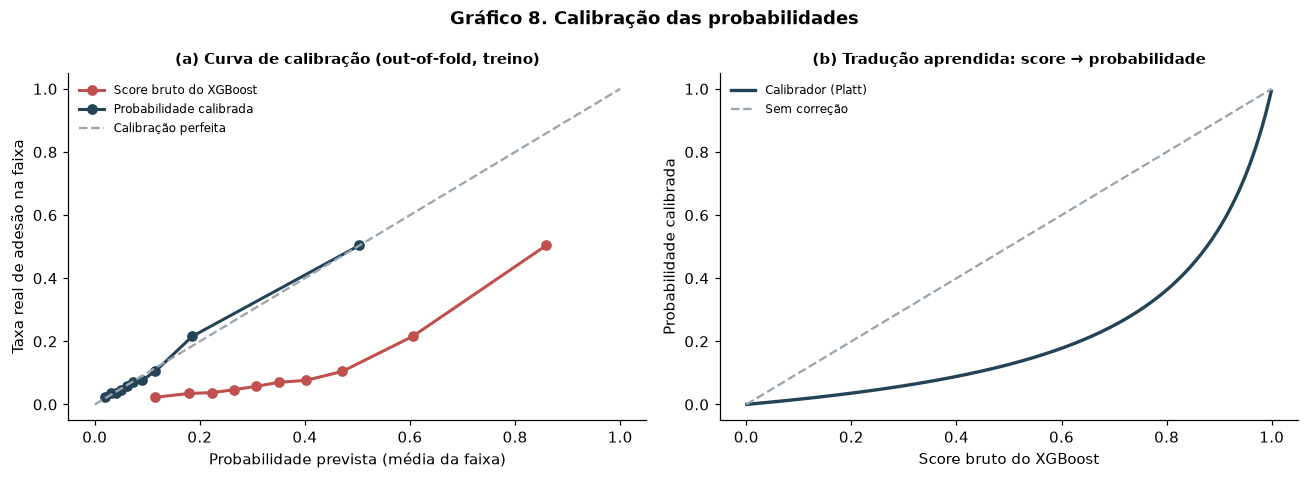

Média prevista: score bruto 0.378 | calibrada 0.117 | taxa real 0.117
Brier score (erro quadrático das probabilidades, menor é melhor): 0.1592 -> 0.0820
Log Loss (menor é melhor): 0.5027 -> 0.2858
ROC-AUC out-of-fold: 0.7995 -> 0.7995 (a ordem não muda)


In [18]:
melhor_pipe = busca.best_estimator_

# Previsões out-of-fold (score bruto): cada cliente do treino é previsto por um modelo que não o viu
proba_oof_bruta = cross_val_predict(melhor_pipe, X_treino, y_treino, cv=cv, method='predict_proba')[:, 1]

def logit(p):
    # Transforma o score (0 a 1) na escala da sigmoide, onde a calibração de Platt é linear
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

calibrador = LogisticRegression(C=1e6).fit(logit(proba_oof_bruta), y_treino)
proba_oof = calibrador.predict_proba(logit(proba_oof_bruta))[:, 1]

def prever_proba(X):
    # Probabilidade calibrada = calibrador(score bruto do XGBoost). É o que a API faz.
    return calibrador.predict_proba(logit(melhor_pipe.predict_proba(X)[:, 1]))[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for proba, nome, cor in [(proba_oof_bruta, 'Score bruto do XGBoost', VERMELHO),
                         (proba_oof, 'Probabilidade calibrada', AZUL)]:
    taxa_real, media_prevista = calibration_curve(y_treino, proba, n_bins=10, strategy='quantile')
    axes[0].plot(media_prevista, taxa_real, marker='o', color=cor, lw=2, label=nome)
axes[0].plot([0, 1], [0, 1], color=CINZA, ls='--', label='Calibração perfeita')
axes[0].set_xlabel('Probabilidade prevista (média da faixa)'); axes[0].set_ylabel('Taxa real de adesão na faixa')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_title('(a) Curva de calibração (out-of-fold, treino)', fontsize=10)

grade_score = np.linspace(0.001, 0.999, 300)
axes[1].plot(grade_score, calibrador.predict_proba(logit(grade_score))[:, 1], color=AZUL, lw=2.2, label='Calibrador (Platt)')
axes[1].plot([0, 1], [0, 1], color=CINZA, ls='--', label='Sem correção')
axes[1].set_xlabel('Score bruto do XGBoost'); axes[1].set_ylabel('Probabilidade calibrada')
axes[1].legend(frameon=False, fontsize=8, loc='upper left')
axes[1].set_title('(b) Tradução aprendida: score → probabilidade', fontsize=10)
fig.suptitle('Gráfico 8. Calibração das probabilidades', fontweight='bold')
fig.tight_layout()
salvar(fig, 'g8_calibracao'); plt.show()

print(f'Média prevista: score bruto {proba_oof_bruta.mean():.3f} | calibrada {proba_oof.mean():.3f} | taxa real {y_treino.mean():.3f}')
print(f'Brier score (erro quadrático das probabilidades, menor é melhor): '
      f'{brier_score_loss(y_treino, proba_oof_bruta):.4f} -> {brier_score_loss(y_treino, proba_oof):.4f}')
print(f'Log Loss (menor é melhor): {log_loss(y_treino, proba_oof_bruta):.4f} -> {log_loss(y_treino, proba_oof):.4f}')
print(f'ROC-AUC out-of-fold: {roc_auc_score(y_treino, proba_oof_bruta):.4f} -> {roc_auc_score(y_treino, proba_oof):.4f} (a ordem não muda)')

**Leitura do Gráfico 8.** No painel (a), a linha vermelha (score bruto) fica bem **abaixo** da diagonal: quando o XGBoost diz 40%, a taxa real daquele grupo de clientes é muito menor. Em média, o score bruto é **0,38**, mais de três vezes a taxa real de **0,117**. Depois da calibração (linha azul), os pontos ficam **próximos da diagonal**: quando o modelo diz 50%, cerca de metade daquele grupo de fato contrata. O **Brier score** e o **Log Loss** (a métrica de probabilidade vista na Unidade 3) caem quase pela metade.

O painel (b) mostra a "tradução" aprendida. Ela é **crescente**: quem tinha score maior continua com probabilidade maior, então a **ordem dos clientes não muda** e o ROC-AUC fica idêntico. A calibração muda o **significado** do número, não a capacidade de ordenar. A partir daqui, todas as probabilidades do notebook e da interface são as calibradas.

### 6.3 Escolha do limiar de decisão

O limiar padrão de 0,5 não tem nada de especial. A introdução definiu que **perder uma venda (FN) custa mais do que uma ligação à toa (FP)**. Por isso o critério é o **F2**, a média entre Precisão e Recall que dá **peso dobrado ao Recall** (o F1 dá peso igual). É a mesma lógica da Tarefa 3, em que baixamos o limiar para não perder pacientes doentes. O limiar é escolhido nas probabilidades calibradas *out-of-fold* do treino, **sem tocar no teste**.

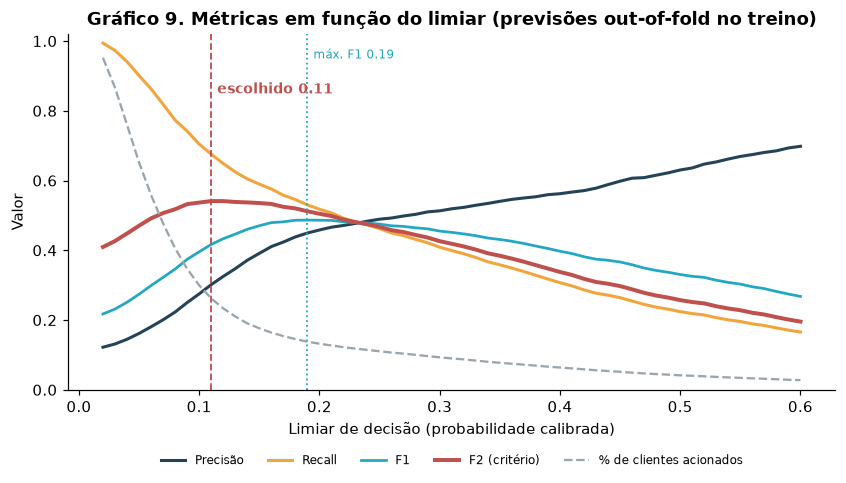

Limiar escolhido (máximo F2 out-of-fold): 0.11 | taxa média de adesão: 0.117
Para comparação, o máximo do F1 ficaria em 0.19


,limiar,Precisão,Recall,F1,F2,% clientes acionados
3,0.05,0.162,0.901,0.274,0.471,0.652
6,0.08,0.223,0.773,0.346,0.518,0.406
9,0.11,0.301,0.675,0.417,0.541,0.262
13,0.15,0.391,0.590,0.470,0.536,0.176
17,0.19,0.450,0.530,0.487,0.512,0.138
28,0.30,0.513,0.409,0.455,0.426,0.093
48,0.50,0.630,0.224,0.331,0.257,0.042


In [19]:
limiares = np.round(np.arange(0.02, 0.61, 0.01), 2)
curva = pd.DataFrame({
    'limiar': limiares,
    'Precisão': [precision_score(y_treino, proba_oof >= t, zero_division=0) for t in limiares],
    'Recall': [recall_score(y_treino, proba_oof >= t) for t in limiares],
    'F1': [f1_score(y_treino, proba_oof >= t) for t in limiares],
    'F2': [fbeta_score(y_treino, proba_oof >= t, beta=2) for t in limiares],
    '% clientes acionados': [(proba_oof >= t).mean() for t in limiares],
})
LIMIAR = float(curva.loc[curva['F2'].idxmax(), 'limiar'])      # critério escolhido (Recall pesa 2x)
LIMIAR_F1 = float(curva.loc[curva['F1'].idxmax(), 'limiar'])   # só para comparação

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(curva['limiar'], curva['Precisão'], color=AZUL, lw=2, label='Precisão')
ax.plot(curva['limiar'], curva['Recall'], color=LARANJA, lw=2, label='Recall')
ax.plot(curva['limiar'], curva['F1'], color=TEAL, lw=1.8, label='F1')
ax.plot(curva['limiar'], curva['F2'], color=VERMELHO, lw=2.6, label='F2 (critério)')
ax.plot(curva['limiar'], curva['% clientes acionados'], color=CINZA, lw=1.5, ls='--', label='% de clientes acionados')
ax.axvline(LIMIAR_F1, color=TEAL, ls=':', lw=1.2)
ax.text(LIMIAR_F1 + 0.005, 0.95, f'máx. F1 {LIMIAR_F1:.2f}', color=TEAL, fontsize=8)
ax.axvline(LIMIAR, color=VERMELHO, ls='--', lw=1.2)
ax.text(LIMIAR + 0.005, 0.85, f'escolhido {LIMIAR:.2f}', color=VERMELHO, fontsize=9, fontweight='bold')
ax.set_xlabel('Limiar de decisão (probabilidade calibrada)'); ax.set_ylabel('Valor'); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.15), fontsize=8)
ax.set_title('Gráfico 9. Métricas em função do limiar (previsões out-of-fold no treino)')
salvar(fig, 'g9_limiar'); plt.show()

print(f'Limiar escolhido (máximo F2 out-of-fold): {LIMIAR:.2f} | taxa média de adesão: {y_treino.mean():.3f}')
print(f'Para comparação, o máximo do F1 ficaria em {LIMIAR_F1:.2f}')
curva[curva['limiar'].isin([0.05, 0.08, LIMIAR, 0.15, LIMIAR_F1, 0.30, 0.50])].drop_duplicates().round(3)

**Leitura do Gráfico 9.** Subir o limiar torna o modelo mais exigente: a Precisão sobe, o Recall cai e menos clientes entram na fila. O F2 é máximo em **0,11**, praticamente a **taxa média de adesão (11,7%)**. A regra fica fácil de explicar para a equipe comercial: **ligar para quem tem chance acima da média**.

Comparado ao máximo do F1 (0,19), o limiar escolhido aciona mais clientes (cerca de 26% da base, contra 14%) e encontra mais interessados (Recall de cerca de 0,68, contra 0,53). Essa é a troca que o problema pede, já que o FN é o erro mais caro. Se a equipe tiver menos capacidade, basta subir o limiar: a curva mostra o custo de cada escolha. Por isso o limiar fica salvo nos metadados e aparece na interface.

---
## Etapa 7: Avaliação Final no Conjunto de Teste

Agora, **pela primeira e única vez**, o modelo final (XGBoost com os melhores hiperparâmetros, treinado em todo o treino pelo `GridSearchCV`, seguido do calibrador) faz previsões para os 9.043 clientes do teste, que ele nunca viu. Reportamos as métricas no limiar escolhido e, para comparação, no limiar do máximo F1 e no "modelo preguiçoso" que sempre responde "não".

In [20]:
modelo_final = melhor_pipe
proba_teste = prever_proba(X_teste)          # probabilidade calibrada

def metricas(y_true, proba, limiar):
    pred = (proba >= limiar).astype(int)
    return {'Acurácia': accuracy_score(y_true, pred), 'Precisão': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'F2': fbeta_score(y_true, pred, beta=2),
            'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            '% acionados': pred.mean()}

sempre_nao = np.zeros(len(y_teste))           # referência: nunca recomenda ligar
tabela_teste = pd.DataFrame({
    f'Escolhido: máx. F2 ({LIMIAR:.2f})': metricas(y_teste, proba_teste, LIMIAR),
    f'Comparação: máx. F1 ({LIMIAR_F1:.2f})': metricas(y_teste, proba_teste, LIMIAR_F1),
    'Referência: sempre "não"': metricas(y_teste, sempre_nao, 0.5),
}).T
pred_teste = (proba_teste >= LIMIAR).astype(int)
print(classification_report(y_teste, pred_teste, target_names=['Não contratou (0)', 'Contratou (1)'], digits=3))
tabela_teste.round(3)

                   precision    recall  f1-score   support

Não contratou (0)      0.951     0.787     0.861      7985
    Contratou (1)      0.301     0.691     0.419      1058

         accuracy                          0.776      9043
        macro avg      0.626     0.739     0.640      9043
     weighted avg      0.874     0.776     0.809      9043



,Acurácia,Precisão,Recall,F1,F2,ROC-AUC,PR-AUC,% acionados
Escolhido: máx. F2 (0.11),0.776,0.301,0.691,0.419,0.548,0.804,0.464,0.269
Comparação: máx. F1 (0.19),0.872,0.462,0.548,0.502,0.529,0.804,0.464,0.139
"Referência: sempre ""não""",0.883,0.000,0.000,0.000,0.000,0.500,0.117,0.000


**As probabilidades continuam calibradas no teste?** Agrupamos os clientes do teste por faixa de probabilidade prevista e comparamos com a taxa real de adesão de cada faixa.

In [21]:
faixas_prob = pd.cut(proba_teste, [0, 0.05, 0.10, 0.20, 0.40, 0.60, 1.0], include_lowest=True)
tabela_calibracao = (pd.DataFrame({'prevista': proba_teste, 'real': y_teste.values})
                       .groupby(faixas_prob, observed=True)
                       .agg(clientes=('real', 'size'), prob_media_prevista=('prevista', 'mean'), taxa_real=('real', 'mean')))
print(f'Brier score no teste: {brier_score_loss(y_teste, proba_teste):.4f} | Log Loss: {log_loss(y_teste, proba_teste):.4f}')
tabela_calibracao.round(3)

Brier score no teste: 0.0806 | Log Loss: 0.2819


,clientes,prob_media_prevista,taxa_real
"(-0.001, 0.05]",3103,0.033,0.034
"(0.05, 0.1]",3162,0.071,0.057
"(0.1, 0.2]",1587,0.134,0.130
"(0.2, 0.4]",612,0.289,0.366
"(0.4, 0.6]",327,0.489,0.511
"(0.6, 1.0]",252,0.736,0.694


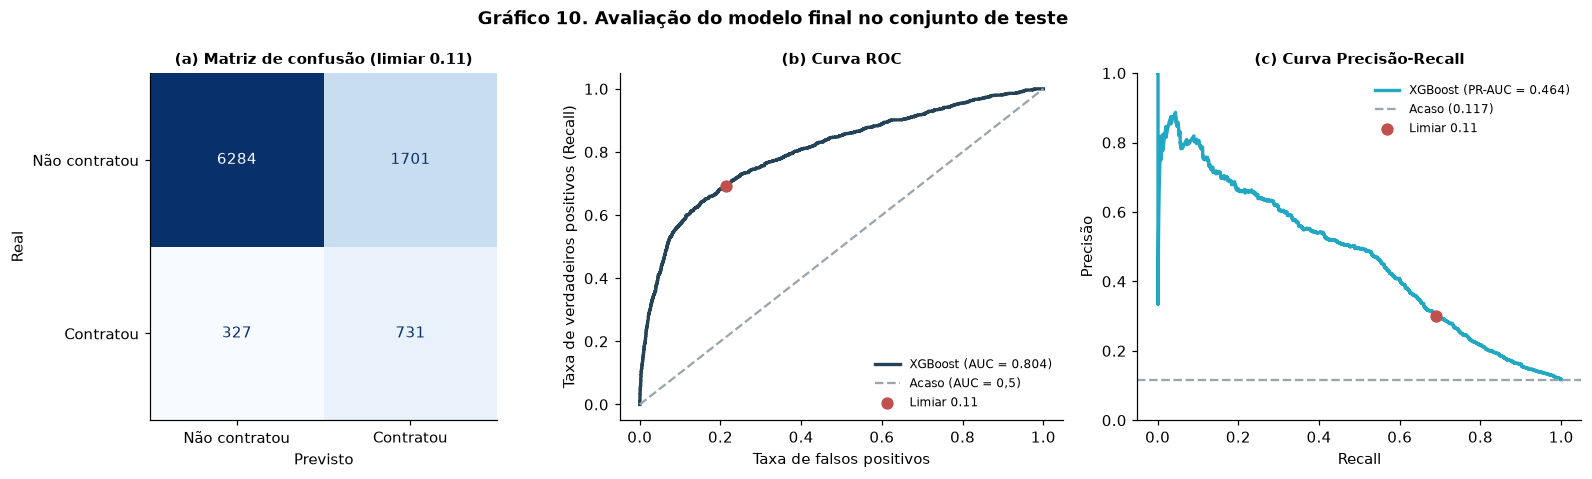

VN=6284  FP=1701  FN=327  VP=731


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# (a) Matriz de confusão
cm = confusion_matrix(y_teste, pred_teste)
ConfusionMatrixDisplay(cm, display_labels=['Não contratou', 'Contratou']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title(f'(a) Matriz de confusão (limiar {LIMIAR:.2f})', fontsize=10)
axes[0].set_xlabel('Previsto'); axes[0].set_ylabel('Real')

# (b) Curva ROC
fpr, tpr, _ = roc_curve(y_teste, proba_teste)
auc_teste = roc_auc_score(y_teste, proba_teste)
axes[1].plot(fpr, tpr, color=AZUL, lw=2.2, label=f'XGBoost (AUC = {auc_teste:.3f})')
axes[1].plot([0, 1], [0, 1], color=CINZA, ls='--', label='Acaso (AUC = 0,5)')
fpr_l = cm[0, 1] / cm[0].sum(); tpr_l = cm[1, 1] / cm[1].sum()
axes[1].scatter([fpr_l], [tpr_l], color=VERMELHO, zorder=5, s=50, label=f'Limiar {LIMIAR:.2f}')
axes[1].set_xlabel('Taxa de falsos positivos'); axes[1].set_ylabel('Taxa de verdadeiros positivos (Recall)')
axes[1].legend(frameon=False, loc='lower right', fontsize=8); axes[1].set_title('(b) Curva ROC', fontsize=10)

# (c) Curva Precisão-Recall
prec, rec, _ = precision_recall_curve(y_teste, proba_teste)
ap_teste = average_precision_score(y_teste, proba_teste)
axes[2].plot(rec, prec, color=TEAL, lw=2.2, label=f'XGBoost (PR-AUC = {ap_teste:.3f})')
axes[2].axhline(y_teste.mean(), color=CINZA, ls='--', label=f'Acaso ({y_teste.mean():.3f})')
axes[2].scatter([recall_score(y_teste, pred_teste)], [precision_score(y_teste, pred_teste)],
                color=VERMELHO, zorder=5, s=50, label=f'Limiar {LIMIAR:.2f}')
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precisão'); axes[2].set_ylim(0, 1)
axes[2].legend(frameon=False, fontsize=8); axes[2].set_title('(c) Curva Precisão-Recall', fontsize=10)

fig.suptitle('Gráfico 10. Avaliação do modelo final no conjunto de teste', fontweight='bold')
fig.tight_layout()
salvar(fig, 'g10_avaliacao_teste'); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'VN={tn}  FP={fp}  FN={fn}  VP={tp}')

**Interpretação da avaliação no teste.**

- As métricas no teste ficam **muito próximas das da validação cruzada** (ROC-AUC 0,804 e PR-AUC 0,464 no teste, contra 0,800 e 0,45 na validação cruzada). O modelo **generaliza** e não houve superajuste ao treino.
- **Calibração:** na maioria das faixas, a probabilidade prevista fica próxima da taxa real (por exemplo, clientes com previsão entre 40% e 60% contratam cerca de 50% das vezes). A maior diferença está na faixa de 20% a 40%, em que o modelo prevê 29% e a taxa real é 37%: ali ele é um pouco conservador. O número que a interface mostra como "chance" é uma boa estimativa, muito mais fiel que o score bruto.
- **Matriz de confusão:** o modelo encontra **69%** dos clientes que de fato contrataram (731 de 1.058), deixando escapar 327. Dos clientes que ele manda ligar, **30%** contratam, cerca de **2,6 vezes** a taxa de uma campanha sem modelo (11,7%). Para isso, aciona 27% da base.
- **Por que não o limiar do F1?** Com 0,19 a Precisão sobe para 46%, mas o Recall cai para 55%: seriam cerca de 150 vendas perdidas a mais no teste. Como o FN é o erro mais caro, o F2 é a escolha coerente com o problema.
- **A acurácia é menor que a do "modelo preguiçoso", e isso é esperado.** O modelo que sempre responde "não" acerta **88,3%** sem encontrar nenhum cliente (Recall 0). O modelo escolhido tem acurácia de 0,78 porque, de propósito, aceita ligações a mais (FP) para perder menos vendas (FN). É a demonstração prática de por que a acurácia não foi usada como critério.
- **Curva ROC:** bem acima da diagonal do acaso. O ponto vermelho mostra onde o limiar escolhido opera.
- **Curva Precisão-Recall:** a mais honesta com classes desbalanceadas. A linha do acaso fica em 0,117; o modelo fica muito acima em toda a faixa de Recall.

### 7.1 Visão de negócio: curva de ganho

A pergunta prática do gerente de campanha é: *"se eu só tiver capacidade para ligar para X% da base, quantos dos interessados eu alcanço?"*. A curva de ganho ordena os clientes do teste do maior para o menor score e responde exatamente isso.

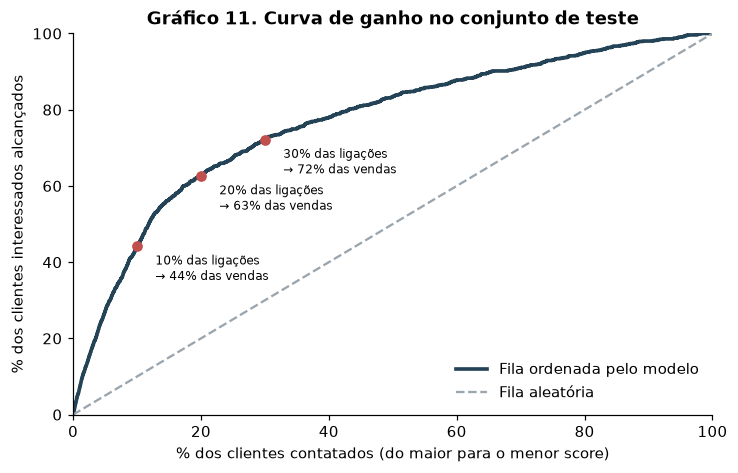

Ligando para os 10% de maior score: 44.1% dos interessados (lift = 4.4x)
Ligando para os 20% de maior score: 62.6% dos interessados (lift = 3.1x)
Ligando para os 30% de maior score: 72.1% dos interessados (lift = 2.4x)
Ligando para os 50% de maior score: 83.3% dos interessados (lift = 1.7x)


In [23]:
ordem_score = np.argsort(-proba_teste)
captura = np.cumsum(y_teste.values[ordem_score]) / y_teste.sum()
frac = np.arange(1, len(captura) + 1) / len(captura)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(frac * 100, captura * 100, color=AZUL, lw=2.4, label='Fila ordenada pelo modelo')
ax.plot([0, 100], [0, 100], color=CINZA, ls='--', label='Fila aleatória')
for p in [0.10, 0.20, 0.30]:
    c = captura[int(p * len(captura)) - 1]
    ax.scatter(p * 100, c * 100, color=VERMELHO, zorder=5)
    ax.annotate(f'{p:.0%} das ligações\n→ {c:.0%} das vendas', (p * 100, c * 100),
                textcoords='offset points', xytext=(12, -22), fontsize=8)
ax.set_xlabel('% dos clientes contatados (do maior para o menor score)')
ax.set_ylabel('% dos clientes interessados alcançados')
ax.legend(frameon=False, loc='lower right'); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title('Gráfico 11. Curva de ganho no conjunto de teste')
salvar(fig, 'g11_ganho'); plt.show()

for p in [0.10, 0.20, 0.30, 0.50]:
    c = captura[int(p * len(captura)) - 1]
    print(f'Ligando para os {p:.0%} de maior score: {c:.1%} dos interessados (lift = {c / p:.1f}x)')

**Leitura do Gráfico 11.** Ligando só para os **20% de clientes com maior score**, o banco alcança **63%** de todos os interessados, um *lift* de 3,1 vezes sobre uma fila aleatória. Com 10% das ligações já alcança 44% (lift 4,4) e, com 30%, 72%. É esse o valor de negócio do modelo: **o mesmo resultado comercial com muito menos ligações**, ou mais vendas com a mesma equipe.

### 7.2 Quais variáveis o modelo mais usa?

Somamos a importância (*gain*) do XGBoost de todas as colunas *one-hot* que vêm da mesma variável original, para ler o resultado na linguagem do negócio.

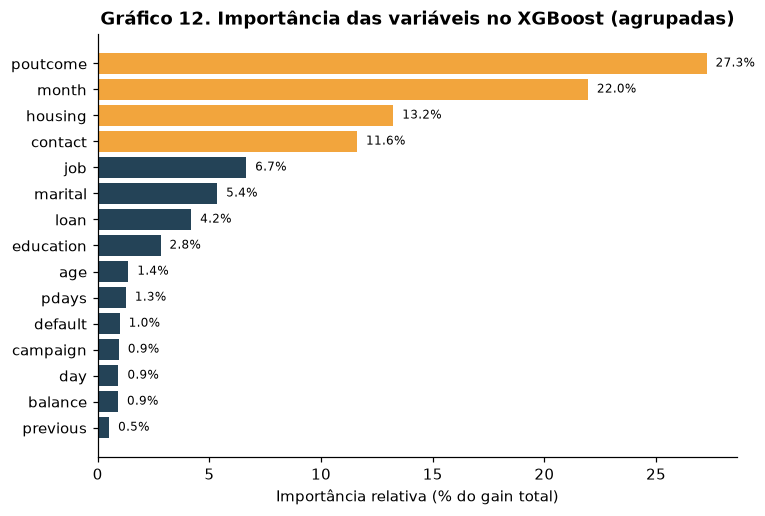

Top 10 colunas one-hot individuais:
cat__poutcome_success    0.255
cat__contact_unknown     0.098
cat__housing_yes         0.083
cat__housing_no          0.049
cat__month_mar           0.034
cat__month_oct           0.030
cat__marital_single      0.028
cat__loan_yes            0.025
cat__month_jun           0.024
cat__month_sep           0.023
dtype: float32


In [24]:
nomes = modelo_final.named_steps['preprocessador'].get_feature_names_out()
importancia = pd.Series(modelo_final.named_steps['modelo'].feature_importances_, index=nomes)
original = [n.split('__', 1)[1] for n in nomes]
original = [next(c for c in CATEGORICAS if o.startswith(c + '_')) if n.startswith('cat__') else o
            for n, o in zip(nomes, original)]
imp_original = importancia.groupby(original).sum().sort_values()
imp_original = imp_original / imp_original.sum()

fig, ax = plt.subplots(figsize=(7.5, 5))
cores = [LARANJA if v >= imp_original.nlargest(4).min() else AZUL for v in imp_original]
ax.barh(imp_original.index, imp_original.values * 100, color=cores)
for i, v in enumerate(imp_original.values):
    ax.text(v * 100 + 0.4, i, f'{v:.1%}', va='center', fontsize=8)
ax.set_xlabel('Importância relativa (% do gain total)')
ax.set_title('Gráfico 12. Importância das variáveis no XGBoost (agrupadas)')
salvar(fig, 'g12_importancia'); plt.show()

print('Top 10 colunas one-hot individuais:')
print((importancia.sort_values(ascending=False).head(10) / importancia.sum()).round(3))

**Leitura do Gráfico 12.** O modelo confirma o que a EDA sugeria: o **resultado da campanha anterior** (`poutcome`, em especial `success`), o **mês**, o **financiamento imobiliário** (`housing`) e o **meio de contato** (`contact = unknown` é sinal forte de baixa adesão) somam quase três quartos da importância. O financiamento imobiliário não apareceu nos gráficos da EDA, mas faz sentido de negócio: quem paga financiamento adere **7,7%**, contra **16,7%** de quem não paga (sobra menos dinheiro para aplicar). Variáveis de perfil como profissão, idade e saldo contribuem, mas cada uma pesa menos. A importância por *gain* mede o quanto o modelo usa cada variável, não causalidade: um mês com alta taxa não "causa" adesão, ele reflete a estratégia da campanha naquele período.

### 7.3 Teste de robustez: e se o modelo for usado no futuro?

O split aleatório mistura clientes de 2008 a 2010 no treino e no teste. Na vida real, o banco treinaria com o **passado** e usaria o modelo no **futuro**. O arquivo da UCI está em **ordem cronológica** (maio de 2008 a novembro de 2010), então dá para simular isso: treinamos a **mesma configuração** com os 80% iniciais do arquivo e avaliamos nos 20% finais. É um diagnóstico extra, **não** usado para escolher nada.

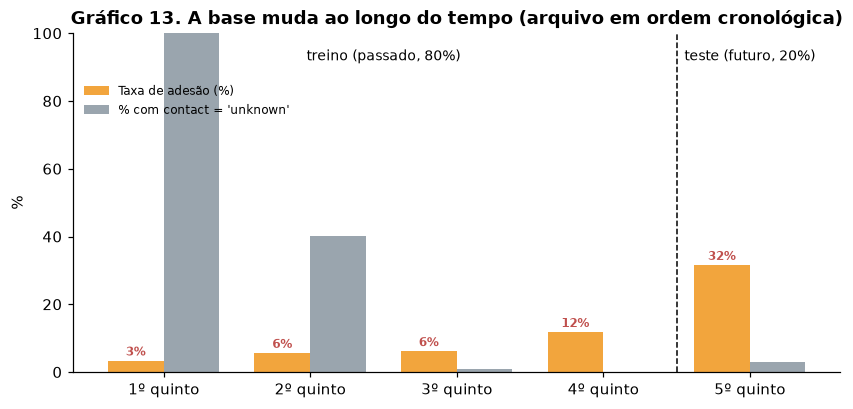

Taxa de adesão: passado 6.7% | futuro 31.6%
Split aleatório (Etapa 7): ROC-AUC 0.804
Split temporal           : ROC-AUC 0.663 | PR-AUC 0.467 (acaso = 0.316)


In [25]:
# Como a base muda ao longo do tempo: cada quinto do arquivo é um período
periodo = np.arange(len(dados)) * 5 // len(dados)
evolucao = dados.groupby(periodo).agg(taxa_adesao=('alvo', 'mean'),
                                      contato_unknown=('contact', lambda s: (s == 'unknown').mean()))
evolucao.index = [f'{i + 1}º quinto' for i in evolucao.index]

corte = int(len(dados) * 0.8)
X_passado, y_passado = X.iloc[:corte], y.iloc[:corte]
X_futuro, y_futuro = X.iloc[corte:], y.iloc[corte:]
modelo_temporal = clone(melhor_pipe).fit(X_passado, y_passado)    # mesmos hiperparâmetros
proba_futuro = modelo_temporal.predict_proba(X_futuro)[:, 1]
auc_temporal = roc_auc_score(y_futuro, proba_futuro)
pr_temporal = average_precision_score(y_futuro, proba_futuro)

fig, ax = plt.subplots(figsize=(9, 4))
largura = 0.38; pos = np.arange(len(evolucao))
ax.bar(pos - largura / 2, evolucao['taxa_adesao'] * 100, largura, color=LARANJA, label='Taxa de adesão (%)')
ax.bar(pos + largura / 2, evolucao['contato_unknown'] * 100, largura, color=CINZA, label="% com contact = 'unknown'")
for x, v in zip(pos, evolucao['taxa_adesao']):
    ax.text(x - largura / 2, v * 100 + 1.5, f'{v:.0%}', ha='center', fontsize=8, color=VERMELHO, fontweight='bold')
ax.axvline(3.5, color='black', ls='--', lw=1)
ax.text(1.5, 92, 'treino (passado, 80%)', ha='center', fontsize=9)
ax.text(4, 92, 'teste (futuro, 20%)', ha='center', fontsize=9)
ax.set_xticks(pos); ax.set_xticklabels(evolucao.index); ax.set_ylim(0, 100); ax.set_ylabel('%')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0, 0.88), fontsize=8)
ax.set_title('Gráfico 13. A base muda ao longo do tempo (arquivo em ordem cronológica)')
salvar(fig, 'g13_temporal'); plt.show()

print(f'Taxa de adesão: passado {y_passado.mean():.1%} | futuro {y_futuro.mean():.1%}')
print(f'Split aleatório (Etapa 7): ROC-AUC {roc_auc_score(y_teste, proba_teste):.3f}')
print(f'Split temporal           : ROC-AUC {auc_temporal:.3f} | PR-AUC {pr_temporal:.3f} (acaso = {y_futuro.mean():.3f})')

**Leitura do Gráfico 13.** O teste temporal é bem mais duro: o ROC-AUC cai de **0,80 para 0,66**. Há dois motivos:

- **O comportamento muda com o tempo.** A taxa de adesão sobe de cerca de **3%** no início do arquivo para **32%** no último quinto. O modelo aprende um "mundo" de baixa adesão e é testado em outro, bem diferente (*data drift*, visto no ciclo de vida de MLOps da Unidade 1).
- **Algumas variáveis são marcas de período.** `contact = unknown` aparece em **100%** do primeiro quinto e quase some depois: era uma forma de registro do início da campanha, não uma característica do cliente. Do mesmo jeito, `month` não tem o ano, e o mesmo mês corresponde a estratégias diferentes em anos diferentes.

**Consequência prática:** o 0,80 do split aleatório mede o desempenho **dentro do mesmo período**. Para usar o modelo em campanhas futuras, ele precisa ser **retreinado e recalibrado com frequência** e **monitorado**, porque a calibração da Etapa 6 também envelhece se a taxa de adesão mudar. Isso entra nas limitações.

---
## Etapa 8: Exportação do Modelo

Salvamos com `joblib`, na pasta `modelo/`:

| Arquivo | Conteúdo |
|---|---|
| `preprocessador.joblib` | `ColumnTransformer` ajustado no treino: imputadores, **`StandardScaler`** (o *scaler*) e **`OneHotEncoder`** |
| `modelo.joblib` | classificador XGBoost treinado |
| `calibrador.joblib` | calibrador de Platt (Regressão Logística sobre o *logit* do score), que transforma o score em probabilidade real |
| `metadados.json` | lista e ordem das features, categorias válidas, faixas plausíveis, limiar escolhido, métricas de teste e versões das bibliotecas |

A interface (`app/app.py`) carrega esses quatro arquivos **uma única vez** ao iniciar e **nunca retreina** o modelo. As faixas plausíveis dos metadados são usadas pela API para validar a entrada.

In [26]:
preprocessador = modelo_final.named_steps['preprocessador']
classificador = modelo_final.named_steps['modelo']

joblib.dump(preprocessador, PASTA_MODELO / 'preprocessador.joblib')
joblib.dump(classificador, PASTA_MODELO / 'modelo.joblib')
joblib.dump(calibrador, PASTA_MODELO / 'calibrador.joblib')

faixas = {'age': [18, 100], 'balance': [-20000, 200000], 'day': [1, 31],
          'campaign': [1, 100], 'pdays': [-1, 999], 'previous': [0, 300]}
metadados = {
    'projeto': 'Bank Marketing: propensão a contratar depósito a prazo',
    'autor': 'Rafael Brasil',
    'fonte_dados': 'UCI Machine Learning Repository, Bank Marketing (id 222), bank-full.csv',
    'modelo': 'XGBClassifier',
    'hiperparametros': {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()},
    'features_numericas': NUMERICAS,
    'features_categoricas': CATEGORICAS,
    'ordem_features': FEATURES,
    'categorias': {c: sorted(dados[c].unique().tolist()) for c in CATEGORICAS},
    'faixas_numericas': faixas,
    'calibracao': {'metodo': 'Platt: LogisticRegression sobre logit(score do XGBoost), ajustada nas previsões out-of-fold do treino',
                   'coeficiente': round(float(calibrador.coef_[0, 0]), 4),
                   'intercepto': round(float(calibrador.intercept_[0]), 4),
                   'brier_teste': round(float(brier_score_loss(y_teste, proba_teste)), 4),
                   'tabela_teste': [{'faixa': str(f), 'clientes': int(l.clientes),
                                     'prob_media_prevista': round(float(l.prob_media_prevista), 4),
                                     'taxa_real': round(float(l.taxa_real), 4)} for f, l in tabela_calibracao.iterrows()]},
    'criterio_limiar': 'máximo F2 (Recall com peso 2) nas probabilidades calibradas out-of-fold do treino',
    'limiar': LIMIAR,
    'limiar_max_f1': LIMIAR_F1,
    'taxa_base_adesao': round(float(TAXA_GERAL), 4),
    'metricas_teste': {k: round(float(v), 4) for k, v in metricas(y_teste, proba_teste, LIMIAR).items()},
    'metricas_teste_limiar_f1': {k: round(float(v), 4) for k, v in metricas(y_teste, proba_teste, LIMIAR_F1).items()},
    'referencia_sempre_nao': {k: round(float(v), 4) for k, v in metricas(y_teste, sempre_nao, 0.5).items()},
    'matriz_confusao_teste': {'VN': int(tn), 'FP': int(fp), 'FN': int(fn), 'VP': int(tp)},
    'validacao_temporal': {'roc_auc': round(float(auc_temporal), 4), 'pr_auc': round(float(pr_temporal), 4),
                           'taxa_passado': round(float(y_passado.mean()), 4), 'taxa_futuro': round(float(y_futuro.mean()), 4),
                           'taxa_por_quinto': [round(float(v), 4) for v in evolucao['taxa_adesao']]},
    'comparacao_cv': {m: {k: round(float(v), 4) for k, v in linha.items()} for m, linha in tabela_cv.to_dict('index').items()},
    'grid_search': {'melhor_roc_auc_cv': round(float(busca.best_score_), 4)},
    'curva_ganho': {f'{int(p * 100)}%': round(float(captura[int(p * len(captura)) - 1]), 4) for p in [0.1, 0.2, 0.3, 0.5]},
    'tamanhos': {'total': int(len(dados)), 'treino': int(len(X_treino)), 'teste': int(len(X_teste))},
    'versoes': {'python_sklearn': sklearn.__version__, 'xgboost': xgboost.__version__,
                'pandas': pd.__version__, 'numpy': np.__version__, 'joblib': joblib.__version__},
}
(PASTA_MODELO / 'metadados.json').write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding='utf-8')

for arq in sorted(PASTA_MODELO.iterdir()):
    print(f'{arq.name:<24} {arq.stat().st_size / 1024:8.1f} KB')

calibrador.joblib             0.8 KB
metadados.json                5.6 KB
modelo.joblib               348.2 KB
preprocessador.joblib         5.6 KB


**Teste de sanidade:** recarregamos os arquivos do disco, como a API fará, e conferimos que as previsões são idênticas às do modelo em memória. Também simulamos um cliente novo.

In [27]:
pre_carregado = joblib.load(PASTA_MODELO / 'preprocessador.joblib')
mod_carregado = joblib.load(PASTA_MODELO / 'modelo.joblib')
cal_carregado = joblib.load(PASTA_MODELO / 'calibrador.joblib')
meta_carregado = json.loads((PASTA_MODELO / 'metadados.json').read_text(encoding='utf-8'))

def prever_do_disco(X):
    score = mod_carregado.predict_proba(pre_carregado.transform(X))[:, 1]
    return cal_carregado.predict_proba(logit(score))[:, 1]

proba_recarregada = prever_do_disco(X_teste)
print('Previsões idênticas às do modelo em memória:', np.allclose(proba_recarregada, proba_teste))

cliente_novo = pd.DataFrame([{
    'age': 62, 'job': 'retired', 'marital': 'married', 'education': 'secondary', 'default': 'no',
    'balance': 3500, 'housing': 'no', 'loan': 'no', 'contact': 'cellular', 'day': 15, 'month': 'oct',
    'campaign': 1, 'pdays': 180, 'previous': 2, 'poutcome': 'success'}])[meta_carregado['ordem_features']]
p = prever_do_disco(cliente_novo)[0]
decisao = 'PRIORIZAR LIGAÇÃO' if p >= meta_carregado['limiar'] else 'baixa prioridade'
print(f'Cliente novo: probabilidade de adesão = {p:.1%} -> {decisao} (limiar {meta_carregado["limiar"]:.2f})')

Previsões idênticas às do modelo em memória: True
Cliente novo: probabilidade de adesão = 77.3% -> PRIORIZAR LIGAÇÃO (limiar 0.11)


---
## Etapa 9: Conclusão

**Resposta ao problema de negócio.** Sim, é possível estimar, **antes da ligação**, a chance de um cliente contratar o depósito a prazo, com qualidade suficiente para priorizar a fila de telemarketing. O modelo final (XGBoost calibrado) atinge ROC-AUC de 0,80 e PR-AUC de 0,46 no conjunto de teste, contra 0,50 e 0,12 do acaso. Na prática, ligar para os 20% de clientes com maior probabilidade alcança 63% dos interessados. Com a regra escolhida ("ligar para quem tem chance acima de 11%"), o banco aciona 27% da base, encontra 69% dos clientes que contratariam, e 30% das ligações viram venda, cerca de 2,6 vezes a taxa de uma campanha sem modelo (11,7%).

**Justificativa das escolhas.**

1. **Remoção de `duration`:** foi a decisão mais importante do projeto. A coluna é a mais correlacionada com o alvo, mas só existe depois da ligação. Mantê-la daria métricas infladas e um modelo inutilizável na prática (*data leakage*).
2. **`'unknown'` como categoria:** a EDA mostrou que `contact = unknown` tem adesão de 4% e `poutcome = unknown` indica cliente novo; imputar a moda apagaria esse sinal.
3. **Pipeline com `ColumnTransformer`:** garante que imputação, escala e encoding sejam aprendidos só no treino de cada dobra, e permite exportar exatamente o mesmo pré-processamento usado na API.
4. **Métricas:** pelo desbalanceamento (11,7% de positivos), a acurácia foi descartada como critério. O teste mostra o porquê: o modelo que sempre diz "não" tem acurácia de 88,3% e Recall zero, maior que a do modelo escolhido (0,78), que é o único útil. Os modelos foram comparados por ROC-AUC (independe do limiar).
5. **Calibração:** o peso de classe inflava o score (média 0,38 contra taxa real de 0,117). A calibração de Platt, ajustada em previsões *out-of-fold*, transformou o score em probabilidade real (Brier e Log Loss caíram quase pela metade) sem mudar a ordem dos clientes. Isso é essencial porque a interface mostra o número como "chance de contratar".
6. **Limiar pelo F2:** como perder uma venda custa mais do que uma ligação à toa, o limiar maximiza o F2 (Recall com peso dobrado). O resultado, 0,11, coincide com a taxa média de adesão: "ligar para quem tem chance acima da média". Em relação ao máximo do F1, isso evita cerca de 150 vendas perdidas no teste.
7. **Modelo:** XGBoost e Random Forest empataram tecnicamente e superaram a Regressão Logística por captarem relações não lineares (idade em "U") e interações. O XGBoost foi escolhido pela melhor AUC média e pelo arquivo leve para servir na API. O Grid Search trouxe ganho marginal e preferiu árvores rasas, mais simples e menos sujeitas a superajuste.

**Principais descobertas.** O histórico do cliente (ter aceitado na campanha anterior), o meio de contato, o mês da campanha e o financiamento imobiliário são os sinais mais fortes. Estudantes e aposentados aderem bem acima da média, e insistir com muitas ligações para o mesmo cliente traz retorno decrescente. Os meses de maior volume (maio a agosto) têm as piores taxas, o que sugere que a estratégia de "ligar para todos" desperdiça esforço.

**Limitações.**

- **Dados antigos e de um único banco** (Portugal, 2008–2010, período da crise financeira): o comportamento dos clientes e as taxas de juros mudaram, e o modelo precisaria ser revalidado com dados atuais.
- **`month` reflete a estratégia de campanha**, não só sazonalidade: se o banco mudar o calendário ou o público-alvo, a relação aprendida pode deixar de valer.
- **Desempenho no futuro:** no teste temporal (treinar nos 80% mais antigos e testar nos 20% mais recentes), o ROC-AUC cai de 0,80 para **0,66**, porque a taxa de adesão sobe de 3% para 32% ao longo do arquivo e variáveis como `contact = unknown` marcam períodos, não clientes. O 0,80 vale para o mesmo período; em uso real o modelo precisaria ser retreinado e recalibrado com frequência.
- A **precisão de 30%** significa que cerca de 7 em cada 10 ligações recomendadas ainda resultam em recusa. É o preço escolhido para perder menos vendas: o modelo prioriza, não garante.
- O peso 2 do F2 é uma suposição razoável, não um custo medido. Com o custo real de uma ligação e a margem de um depósito, o ideal seria escolher o limiar que maximiza o **lucro esperado**.

**Melhorias futuras.** Incorporar os indicadores macroeconômicos da versão `bank-additional` (taxa Euribor, índice de confiança do consumidor), que ajudam a explicar a mudança da taxa de adesão ao longo do tempo; adotar validação temporal na escolha do modelo; escolher o limiar por análise de custo-benefício; explicar previsões individuais com SHAP na interface; e monitorar o desempenho e a calibração do modelo em produção.

---
**Referências**

- MORO, S.; CORTEZ, P.; RITA, P. A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, v. 62, p. 22–31, 2014.
- MORO, S.; RITA, P.; CORTEZ, P. Bank Marketing [Dataset]. UCI Machine Learning Repository, 2014. DOI: 10.24432/C5K306.
- PLATT, J. Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. *Advances in Large Margin Classifiers*, MIT Press, 1999.
- Documentação: scikit-learn (Pipeline, ColumnTransformer, GridSearchCV, calibração de probabilidades), XGBoost e FastAPI.

---
### Registro do uso de IA

| Item | Descrição |
|---|---|
| Ferramenta | Claude (Anthropic), via Claude Code |
| Como foi usada | O aluno escolheu a base (Bank Marketing, UCI), a técnica (classificação) e a interface (FastAPI + HTML). A IA escreveu o código do notebook, da API e da página web, executou os experimentos e redigiu as interpretações e o relatório, a pedido do aluno |
| Verificação | Notebook executado do início ao fim sem erros; previsões do modelo recarregado conferidas com as do modelo em memória; API testada com entradas válidas e inválidas |
| Revisão crítica | A pedido do aluno, a IA revisou o projeto e recalculou os números de forma independente. A revisão levou a quatro mudanças: calibração das probabilidades (Etapa 6.2), limiar pelo F2, coerente com o custo maior do FN (Etapa 6.3), comparação explícita com o modelo "sempre não" (Etapa 7) e teste temporal (Etapa 7.3) |
| Revisão do aluno | *(a preencher pelo aluno após revisar o material)* |